# LightGBM con features geoespaciales

**Escenario:** geo (variables base + `distancia_*` + `cluster_zona`).

Se reutiliza `num_leaves=63`, el mejor valor de la baseline, con el mismo split y semilla. LightGBM acepta etiquetas de texto, por lo que no hace falta codificar `price_range`.

- Entrada: `data/processed/airprice_features.csv`
- Salidas: `reports/lightgbm_features_metricas.csv`, importancia y matriz de confusión.

In [1]:
import sys
sys.path.append('../..')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

from src.model_features import (
    PARAMS_BASE,
    construir_lgbm_features,
    evaluar_modelo_ordinal,
    importancia_variables,
    metricas_a_fila,
)
from src.preprocessing_features import FEATURES_PATH, preparar_dataset_features
from src.utils import (
    CLASES,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    guardar_modelo,
    split_estratificado,
)

sns.set_theme(style='whitegrid')
fijar_semilla(SEED)
print('Semilla:', SEED)

Semilla: 42


In [2]:
df = preparar_dataset_features(cargar_dataset(FEATURES_PATH))
print('Filas:', df.shape[0], 'Columnas:', df.shape[1])

X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target='price_range',
    excluir=['price_clean', 'id'],
    seed=SEED,
)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

Filas: 61617 Columnas: 29
Train: (43131, 28) Val: (9243, 28) Test: (9243, 28)


In [3]:
params = dict(PARAMS_BASE['lightgbm'])
print('Hiperparámetros baseline:', params)

modelo = construir_lgbm_features(X_train, **params)
modelo.fit(X_train, y_train)

met_val = evaluar_modelo_ordinal(y_val, modelo.predict(X_val))
print({k: round(v, 4) for k, v in met_val.items() if k != 'matriz_confusion'})

Hiperparámetros baseline: {'n_estimators': 100, 'learning_rate': 0.1, 'num_leaves': 63}
{'accuracy': 0.6864, 'balanced_accuracy': 0.686, 'f1_macro': 0.6847, 'f1_weighted': 0.685, 'accuracy_adjacent': 0.9688, 'mae_ordinal': 0.3484, 'qwk': 0.8316}


{'accuracy': 0.6906, 'balanced_accuracy': 0.6902, 'f1_macro': 0.6892, 'f1_weighted': 0.6895, 'accuracy_adjacent': 0.9705, 'mae_ordinal': 0.345, 'qwk': 0.83}


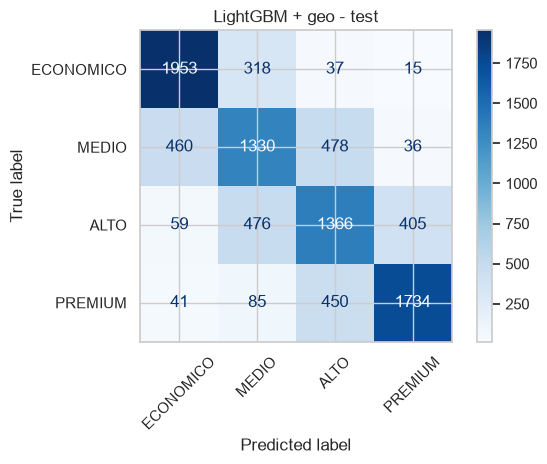

In [4]:
y_pred = modelo.predict(X_test)
met_test = evaluar_modelo_ordinal(y_test, y_pred)
print({k: round(v, 4) for k, v in met_test.items() if k != 'matriz_confusion'})

ConfusionMatrixDisplay(
    met_test['matriz_confusion'], display_labels=CLASES
).plot(cmap='Blues', values_format='d')
plt.title('LightGBM + geo - test')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'lightgbm_features_matriz_confusion.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

                          variable  importancia
0            num__availability_365       2428.0
1             num__amenities_count       1902.0
2           num__reviews_per_month       1868.0
3                    num__latitude       1862.0
4      num__distancia_hyde_park_km       1676.0
5         num__distancia_centro_km       1444.0
6    num__distancia_kings_cross_km       1353.0
7           num__number_of_reviews       1330.0
8        num__review_scores_rating       1328.0
9   num__distancia_canary_wharf_km       1283.0
10             num__minimum_nights       1193.0
11      num__distancia_heathrow_km       1114.0
12               num__accommodates        949.0
13                  num__longitude        913.0
14                   num__bedrooms        555.0


C:\Users\user\AppData\Local\Temp\ipykernel_3112\3414150663.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top, x='importancia', y='variable', palette='viridis')


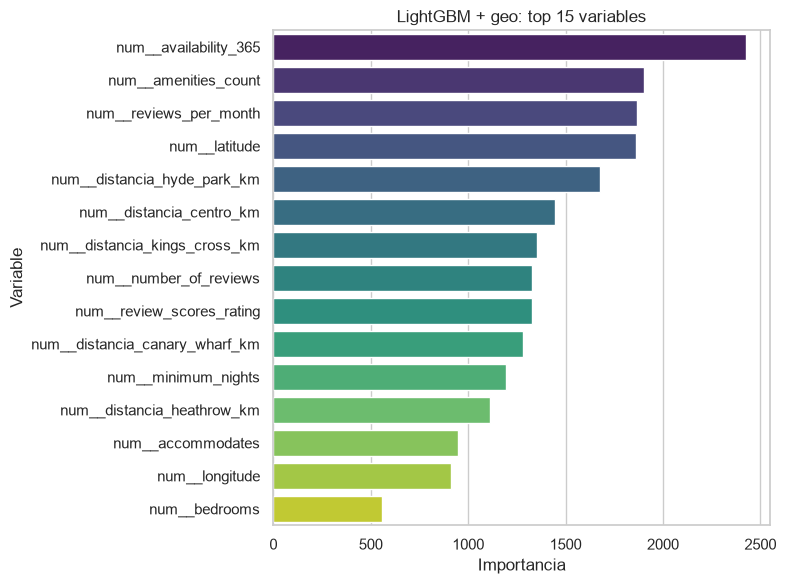

In [5]:
importancia = importancia_variables(modelo)
importancia.to_csv(
    REPORTS_DIR / 'lightgbm_features_importancia.csv', index=False
)
print(importancia.head(15))

top = importancia.head(15)
plt.figure(figsize=(8, 6))
sns.barplot(data=top, x='importancia', y='variable', palette='viridis')
plt.title('LightGBM + geo: top 15 variables')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'lightgbm_features_importancia.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

In [6]:
fila = metricas_a_fila(
    'lightgbm_features',
    met_test,
    escenario='geo',
    **params,
)
pd.DataFrame([fila]).to_csv(
    REPORTS_DIR / 'lightgbm_features_metricas.csv', index=False
)

ruta = guardar_modelo(modelo, 'lightgbm_features')
print('Métricas y matriz guardadas en:', REPORTS_DIR)
print('Modelo guardado en:', ruta)

Métricas y matriz guardadas en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\reports
Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\lightgbm_features.joblib


## Lectura de resultados

- LightGBM fue el mejor baseline (accuracy ≈ 0.688). El escenario geo debe compararse contra `reports/lightgbm_metricas_test.csv`.
- Si la mejora es menor a ±0.005, está dentro del ruido de un único split; la conclusión debe basarse también en la ablación de `notebooks/evaluation/02_evaluacion_modelos_features.ipynb`.